In [1]:
%pip install arabic-reshaper python-bidi


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


دانلود فایل سفرها از سرور...
دانلود جدول مناطق...
گزارش ابعاد اولیه داده سفرها: 3,403,766 سطر و 19 ستون
گزارش ابعاد جدول مناطق: 265 سطر و 4 ستون


,نام ستون,نوع داده,نقش تحلیلی
0,VendorID,int32,شناسه طبقه‌بندی / شرکت ارائه‌دهنده سرویس
1,PULocationID,int32,شناسه مکانی سوار شدن (کلید خارجی به جدول مناطق)
2,DOLocationID,int32,شناسه مکانی پیاده شدن (کلید خارجی به جدول مناطق)
3,RatecodeID,float64,شناسه/کد نرخ تعرفه سفر
4,payment_type,int64,شناسه طبقه‌بندی روش پرداخت
5,tpep_pickup_datetime,datetime64[us],متغیر زمانی (شروع سفر)
6,tpep_dropoff_datetime,datetime64[us],متغیر زمانی (پایان سفر)
7,passenger_count,float64,متغیر عددی گسسته (تعداد مسافر)
8,trip_distance,float64,متغیر عددی پیوسته (مسافت طی شده به مایل)
9,fare_amount,float64,متغیر پیوسته مالی (مبلغ پایه کرایه)


,شاخص ممیزی,تعداد رخداد,درصد از کل,تصمیم اولیه / استراتژی برخورد
0,سطرهای کاملاً تکراری (Duplicate Rows),0,0.0000%,در فاز دوم پیش‌پردازش، رکوردهای کاملاً تکراری ...
1,مقادیر گمشده تعداد مسافر (passenger_count IS N...,87619,2.574%,ثبت توسط راننده انجام نشده؛ جایگزینی با مقدار ...
2,مدت زمان منفی یا صفر (duration <= 0),1453,0.043%,خطای ساعت سیستم؛ در فاز پیش‌پردازش حذف می‌شوند...
3,مسافت ناممکن و صفر (trip_distance <= 0),48528,1.426%,سفرهای لغو شده؛ برای مدل تقاضای ترافیک نامعتبر...
4,سرعت‌های فیزیکی ناممکن (speed > 80 mph),2325,0.068%,ناشی از ثبت غلط مسافت یا مدت سفر؛ در گام تمیزک...
5,کرایه غیرمنطقی یا منفی (total_amount <= 0),30363,0.892%,کرایه‌های مرجوعی، خطا در پوز یا لغوی؛ در مدلسا...
6,سفرهای خارج از بازه زمانی مطالعه (Not in March...,189,0.006%,ثبت اشتباه تاریخ یا خارج از محدوده هدف؛ در مرح...
7,نقاط پرت آماری مسافت سفر (Outliers via 1.5*IQR),442468,12.999%,بررسی به عنوان سفرهای برون‌شهری معتبر؛ به‌جای ...


,متغیر,تعداد نمونه (N),میانگین (μ),انحراف معیار (σ),میانه (Q2),دامنه چارکی (IQR),چارک اول [Q1],چارک سوم [Q3],چولگی (Skewness),کشیدگی (Kurtosis)
0,مسافت سفر (trip_distance - مایل),"3,403,766",3.90,191.69,1.79,2.33,1.05,3.38,799.19,748467.78
1,مدت سفر (duration_min - دقیقه),"3,403,766",16.88,43.79,12.15,12.25,7.40,19.65,31.20,1234.77
2,مبلغ کل پرداختی (total_amount - دلار),"3,403,766",27.80,22.87,20.60,14.06,15.70,29.76,2.93,44.28
3,تقاضای ساعتی منطقه (hourly_trip_count),"75,132",45.30,77.77,6.00,55.00,1.00,56.00,2.53,7.55


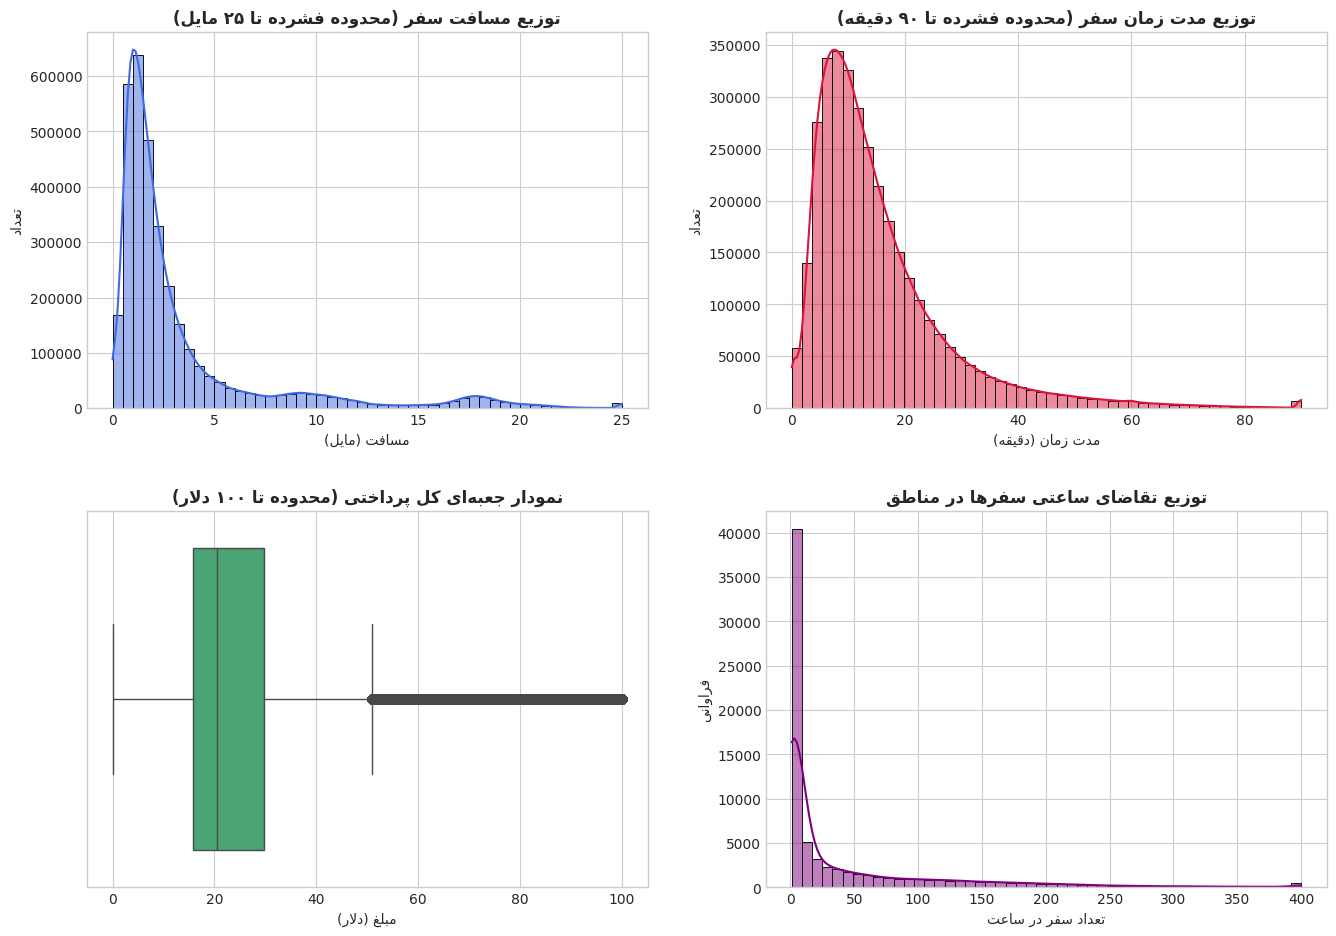


[وضعیت] تمامی ۳ بخش با جزئیات کامل، با مستندات مربوطه و بدون حذف داده اجرا شدند.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import os
from IPython.display import display


import arabic_reshaper
from bidi.algorithm import get_display

def fa(text):
    """اصلاح خودکار جهت و اتصال حروف فارسی برای رسم در مت‌پلات‌لیب"""
    reshaped_text = arabic_reshaper.reshape(text)
    return get_display(reshaped_text)



# تنظیم استایل پیش‌فرض رسم نمودارها
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'


# ==============================================================================
# بخش ۱: ممیزی ساختار داده 
# ==============================================================================

#بارگذاری فایل‌های اصلی (جدول حقایق سفرها و جدول ابعاد مناطق)
trips_file = "yellow_tripdata_2023-03.parquet"
lookup_file = "taxi_zone_lookup.csv"

# دانلود در صورت عدم وجود روی حافظه
if not os.path.exists(trips_file):
    print("دانلود فایل سفرها از سرور...")
    urllib.request.urlretrieve(
        "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-03.parquet", 
        trips_file
    )

if not os.path.exists(lookup_file):
    print("دانلود جدول مناطق...")
    urllib.request.urlretrieve(
        "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv", 
        lookup_file
    )

# بارگذاری از روی دیسک

df_raw = pd.read_parquet(trips_file)
df_zones = pd.read_csv(lookup_file)

# ابعاد داده
n_rows, n_cols = df_raw.shape
print("=" * 80)
print(f"گزارش ابعاد اولیه داده سفرها: {n_rows:,} سطر و {n_cols} ستون")
print(f"گزارش ابعاد جدول مناطق: {df_zones.shape[0]} سطر و {df_zones.shape[1]} ستون")
print("=" * 80)

# دسته‌بندی و ممیزی صریح نوع متغیرها
schema_audit = [
    {"نام ستون": "VendorID", "نوع داده": str(df_raw['VendorID'].dtype), "نقش تحلیلی": "شناسه طبقه‌بندی / شرکت ارائه‌دهنده سرویس"},
    {"نام ستون": "PULocationID", "نوع داده": str(df_raw['PULocationID'].dtype), "نقش تحلیلی": "شناسه مکانی سوار شدن (کلید خارجی به جدول مناطق)"},
    {"نام ستون": "DOLocationID", "نوع داده": str(df_raw['DOLocationID'].dtype), "نقش تحلیلی": "شناسه مکانی پیاده شدن (کلید خارجی به جدول مناطق)"},
    {"نام ستون": "RatecodeID", "نوع داده": str(df_raw['RatecodeID'].dtype), "نقش تحلیلی": "شناسه/کد نرخ تعرفه سفر"},
    {"نام ستون": "payment_type", "نوع داده": str(df_raw['payment_type'].dtype), "نقش تحلیلی": "شناسه طبقه‌بندی روش پرداخت"},
    {"نام ستون": "tpep_pickup_datetime", "نوع داده": str(df_raw['tpep_pickup_datetime'].dtype), "نقش تحلیلی": "متغیر زمانی (شروع سفر)"},
    {"نام ستون": "tpep_dropoff_datetime", "نوع داده": str(df_raw['tpep_dropoff_datetime'].dtype), "نقش تحلیلی": "متغیر زمانی (پایان سفر)"},
    {"نام ستون": "passenger_count", "نوع داده": str(df_raw['passenger_count'].dtype), "نقش تحلیلی": "متغیر عددی گسسته (تعداد مسافر)"},
    {"نام ستون": "trip_distance", "نوع داده": str(df_raw['trip_distance'].dtype), "نقش تحلیلی": "متغیر عددی پیوسته (مسافت طی شده به مایل)"},
    {"نام ستون": "fare_amount", "نوع داده": str(df_raw['fare_amount'].dtype), "نقش تحلیلی": "متغیر پیوسته مالی (مبلغ پایه کرایه)"},
    {"نام ستون": "total_amount", "نوع داده": str(df_raw['total_amount'].dtype), "نقش تحلیلی": "متغیر پیوسته مالی (کل مبلغ پرداختی)"}
]

df_schema_summary = pd.DataFrame(schema_audit)
pd.set_option('display.max_columns', None)
display(df_schema_summary)

# توضیح جریان داده و ادغام جداول:
# جدول حقایق (df_raw) از طریق کلیدهای PULocationID و DOLocationID با جدول ابعاد (df_zones['LocationID'])
# مرتبط است. این اتصال به ما اجازه می‌دهد مشخصات منطقه (Borough / Zone / ServiceZone) را متصل کنیم.


# ==============================================================================
# بخش ۲: ممیزی کیفیت داده و تصمیم‌گیری اولیه 
# ==============================================================================

# تبدیل انواع داده‌های زمانی برای استخراج شاخص‌ها
df_raw['tpep_pickup_datetime'] = pd.to_datetime(df_raw['tpep_pickup_datetime'])
df_raw['tpep_dropoff_datetime'] = pd.to_datetime(df_raw['tpep_dropoff_datetime'])
df_raw['duration_min'] = (df_raw['tpep_dropoff_datetime'] - df_raw['tpep_pickup_datetime']).dt.total_seconds() / 60.0
df_raw['speed_mph'] = df_raw['trip_distance'] / (df_raw['duration_min'] / 60.0)

# شناسایی و کمّی‌سازی مقادیر پرت با استفاده از روش دامنه چارکی (IQR) روی مسافت
q1_dist, q3_dist = df_raw['trip_distance'].quantile(0.25), df_raw['trip_distance'].quantile(0.75)
iqr_dist = q3_dist - q1_dist
outliers_iqr_distance = ((df_raw['trip_distance'] < (q1_dist - 1.5 * iqr_dist)) | 
                         (df_raw['trip_distance'] > (q3_dist + 1.5 * iqr_dist))).sum()

# ارزیابی رکوردهای خارج از بازه زمانی ماه مارس ۲۰۲۳
out_of_month = (~df_raw['tpep_pickup_datetime'].between('2023-03-01', '2023-03-31 23:59:59')).sum()

# جدول جامع ممیزی کیفیت همراه با تصمیم اولیه (بدون فیلتر کردن در این فاز)
quality_records = [
    {
        "شاخص ممیزی": "سطرهای کاملاً تکراری (Duplicate Rows)",
        "تعداد رخداد": df_raw.duplicated().sum(),
        "درصد از کل": f"{(df_raw.duplicated().sum() / n_rows) * 100:.4f}%",
        "تصمیم اولیه / استراتژی برخورد": "در فاز دوم پیش‌پردازش، رکوردهای کاملاً تکراری حذف خواهند شد چون نشان‌دهنده خطای لاگ هستند."
    },
    {
        "شاخص ممیزی": "مقادیر گمشده تعداد مسافر (passenger_count IS NULL)",
        "تعداد رخداد": df_raw['passenger_count'].isna().sum(),
        "درصد از کل": f"{(df_raw['passenger_count'].isna().sum() / n_rows) * 100:.3f}%",
        "تصمیم اولیه / استراتژی برخورد": "ثبت توسط راننده انجام نشده؛ جایگزینی با مقدار میانه (۱) یا استفاده از فلگ گمشده."
    },
    {
        "شاخص ممیزی": "مدت زمان منفی یا صفر (duration <= 0)",
        "تعداد رخداد": (df_raw['duration_min'] <= 0).sum(),
        "درصد از کل": f"{((df_raw['duration_min'] <= 0).sum() / n_rows) * 100:.3f}%",
        "تصمیم اولیه / استراتژی برخورد": "خطای ساعت سیستم؛ در فاز پیش‌پردازش حذف می‌شوند زیرا با منطق فیزیکی سفر ناسازگار است."
    },
    {
        "شاخص ممیزی": "مسافت ناممکن و صفر (trip_distance <= 0)",
        "تعداد رخداد": (df_raw['trip_distance'] <= 0).sum(),
        "درصد از کل": f"{((df_raw['trip_distance'] <= 0).sum() / n_rows) * 100:.3f}%",
        "تصمیم اولیه / استراتژی برخورد": "سفرهای لغو شده؛ برای مدل تقاضای ترافیک نامعتبر بوده و در پیش‌پردازش پالایش می‌شوند."
    },
    {
        "شاخص ممیزی": "سرعت‌های فیزیکی ناممکن (speed > 80 mph)",
        "تعداد رخداد": (df_raw['speed_mph'] > 80).sum(),
        "درصد از کل": f"{((df_raw['speed_mph'] > 80).sum() / n_rows) * 100:.3f}%",
        "تصمیم اولیه / استراتژی برخورد": "ناشی از ثبت غلط مسافت یا مدت سفر؛ در گام تمیزکاری به عنوان داده غیرواقعی حذف خواهند شد."
    },
    {
        "شاخص ممیزی": "کرایه غیرمنطقی یا منفی (total_amount <= 0)",
        "تعداد رخداد": (df_raw['total_amount'] <= 0).sum(),
        "درصد از کل": f"{((df_raw['total_amount'] <= 0).sum() / n_rows) * 100:.3f}%",
        "تصمیم اولیه / استراتژی برخورد": "کرایه‌های مرجوعی، خطا در پوز یا لغوی؛ در مدلسازی جریان مالی فیلتر خواهند شد."
    },
    {
        "شاخص ممیزی": "سفرهای خارج از بازه زمانی مطالعه (Not in March 2023)",
        "تعداد رخداد": out_of_month,
        "درصد از کل": f"{(out_of_month / n_rows) * 100:.3f}%",
        "تصمیم اولیه / استراتژی برخورد": "ثبت اشتباه تاریخ یا خارج از محدوده هدف؛ در مرحله آماده‌سازی به طور دقیق فیلتر خواهد شد."
    },
    {
        "شاخص ممیزی": "نقاط پرت آماری مسافت سفر (Outliers via 1.5*IQR)",
        "تعداد رخداد": outliers_iqr_distance,
        "درصد از کل": f"{(outliers_iqr_distance / n_rows) * 100:.3f}%",
        "تصمیم اولیه / استراتژی برخورد": "بررسی به عنوان سفرهای برون‌شهری معتبر؛ به‌جای حذف کور، اعمال آستانه منطقی (مثلاً مسافت بالای ۱۰۰ مایل)."
    }
]

df_quality_audit = pd.DataFrame(quality_records)
pd.set_option('display.max_columns', None)
display(df_quality_audit)


# ==============================================================================
# بخش ۳: تحلیل اکتشافی تک‌متغیره 
# ==============================================================================

# محاسبه متغیر تقاضای ساعتی خام بر روی تمام داده‌ها
df_raw['pickup_hour'] = df_raw['tpep_pickup_datetime'].dt.floor('h')
hourly_demand = (
    df_raw.groupby(['pickup_hour', 'PULocationID'])
    .size()
    .reset_index(name='hourly_trip_count')
)

# تابع محاسبه آماره‌های توصیفی دقیق
def compute_univariate_metrics(series, feature_name):
    s = series.dropna()
    q1 = s.quantile(0.25)
    q2 = s.quantile(0.50)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    return {
        'متغیر': feature_name,
        'تعداد نمونه (N)': f"{len(s):,}",
        'میانگین (μ)': round(float(s.mean()), 2),
        'انحراف معیار (σ)': round(float(s.std()), 2),
        'میانه (Q2)': round(float(q2), 2),
        'دامنه چارکی (IQR)': round(float(iqr), 2),
        'چارک اول [Q1]': round(float(q1), 2),
        'چارک سوم [Q3]': round(float(q3), 2),
        'چولگی (Skewness)': round(float(s.skew()), 2),      # محاسبه با خود Pandas
        'کشیدگی (Kurtosis)': round(float(s.kurtosis()), 2)  # محاسبه با خود Pandas
    }

metrics_list = [
    compute_univariate_metrics(df_raw['trip_distance'], 'مسافت سفر (trip_distance - مایل)'),
    compute_univariate_metrics(df_raw['duration_min'], 'مدت سفر (duration_min - دقیقه)'),
    compute_univariate_metrics(df_raw['total_amount'], 'مبلغ کل پرداختی (total_amount - دلار)'),
    compute_univariate_metrics(hourly_demand['hourly_trip_count'], 'تقاضای ساعتی منطقه (hourly_trip_count)')
]

df_univariate_metrics = pd.DataFrame(metrics_list)

pd.set_option('display.max_columns', None)
display(df_univariate_metrics)
# رسم نمودارهای مناسب توزیع (هیستوگرام و نمودار جعبه‌ای) برای نمایش شکل توزیع و عدم‌توازن
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# توزیع مسافت سفر
sns.histplot(df_raw['trip_distance'].clip(upper=25), bins=50, kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title(fa('توزیع مسافت سفر (محدوده فشرده تا ۲۵ مایل)'), fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel(fa('مسافت (مایل)'))
axes[0, 0].set_ylabel(fa('تعداد'))

# توزیع مدت زمان سفر
sns.histplot(df_raw['duration_min'].clip(lower=0, upper=90), bins=50, kde=True, ax=axes[0, 1], color='crimson')
axes[0, 1].set_title(fa('توزیع مدت زمان سفر (محدوده فشرده تا ۹۰ دقیقه)'), fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel(fa('مدت زمان (دقیقه)'))
axes[0, 1].set_ylabel(fa('تعداد'))

# توزیع مبلغ کل پرداختی
sns.boxplot(x=df_raw['total_amount'].clip(lower=0, upper=100), ax=axes[1, 0], color='mediumseagreen')
axes[1, 0].set_title(fa('نمودار جعبه‌ای کل پرداختی (محدوده تا ۱۰۰ دلار)'), fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel(fa('مبلغ (دلار)'))

# توزیع متغیر تقاضای ساعتی (Hourly Demand)
sns.histplot(hourly_demand['hourly_trip_count'].clip(upper=400), bins=50, kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title(fa('توزیع تقاضای ساعتی سفرها در مناطق'), fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel(fa('تعداد سفر در ساعت'))
axes[1, 1].set_ylabel(fa('فراوانی'))

plt.tight_layout(pad=3.0)
plt.savefig('univariate_eda_distributions.png', dpi=300)
plt.show()

print("\n[وضعیت] تمامی ۳ بخش با جزئیات کامل، با مستندات مربوطه و بدون حذف داده اجرا شدند.")


C:\Users\RK\AppData\Local\Temp\ipykernel_13676\511575176.py:117: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


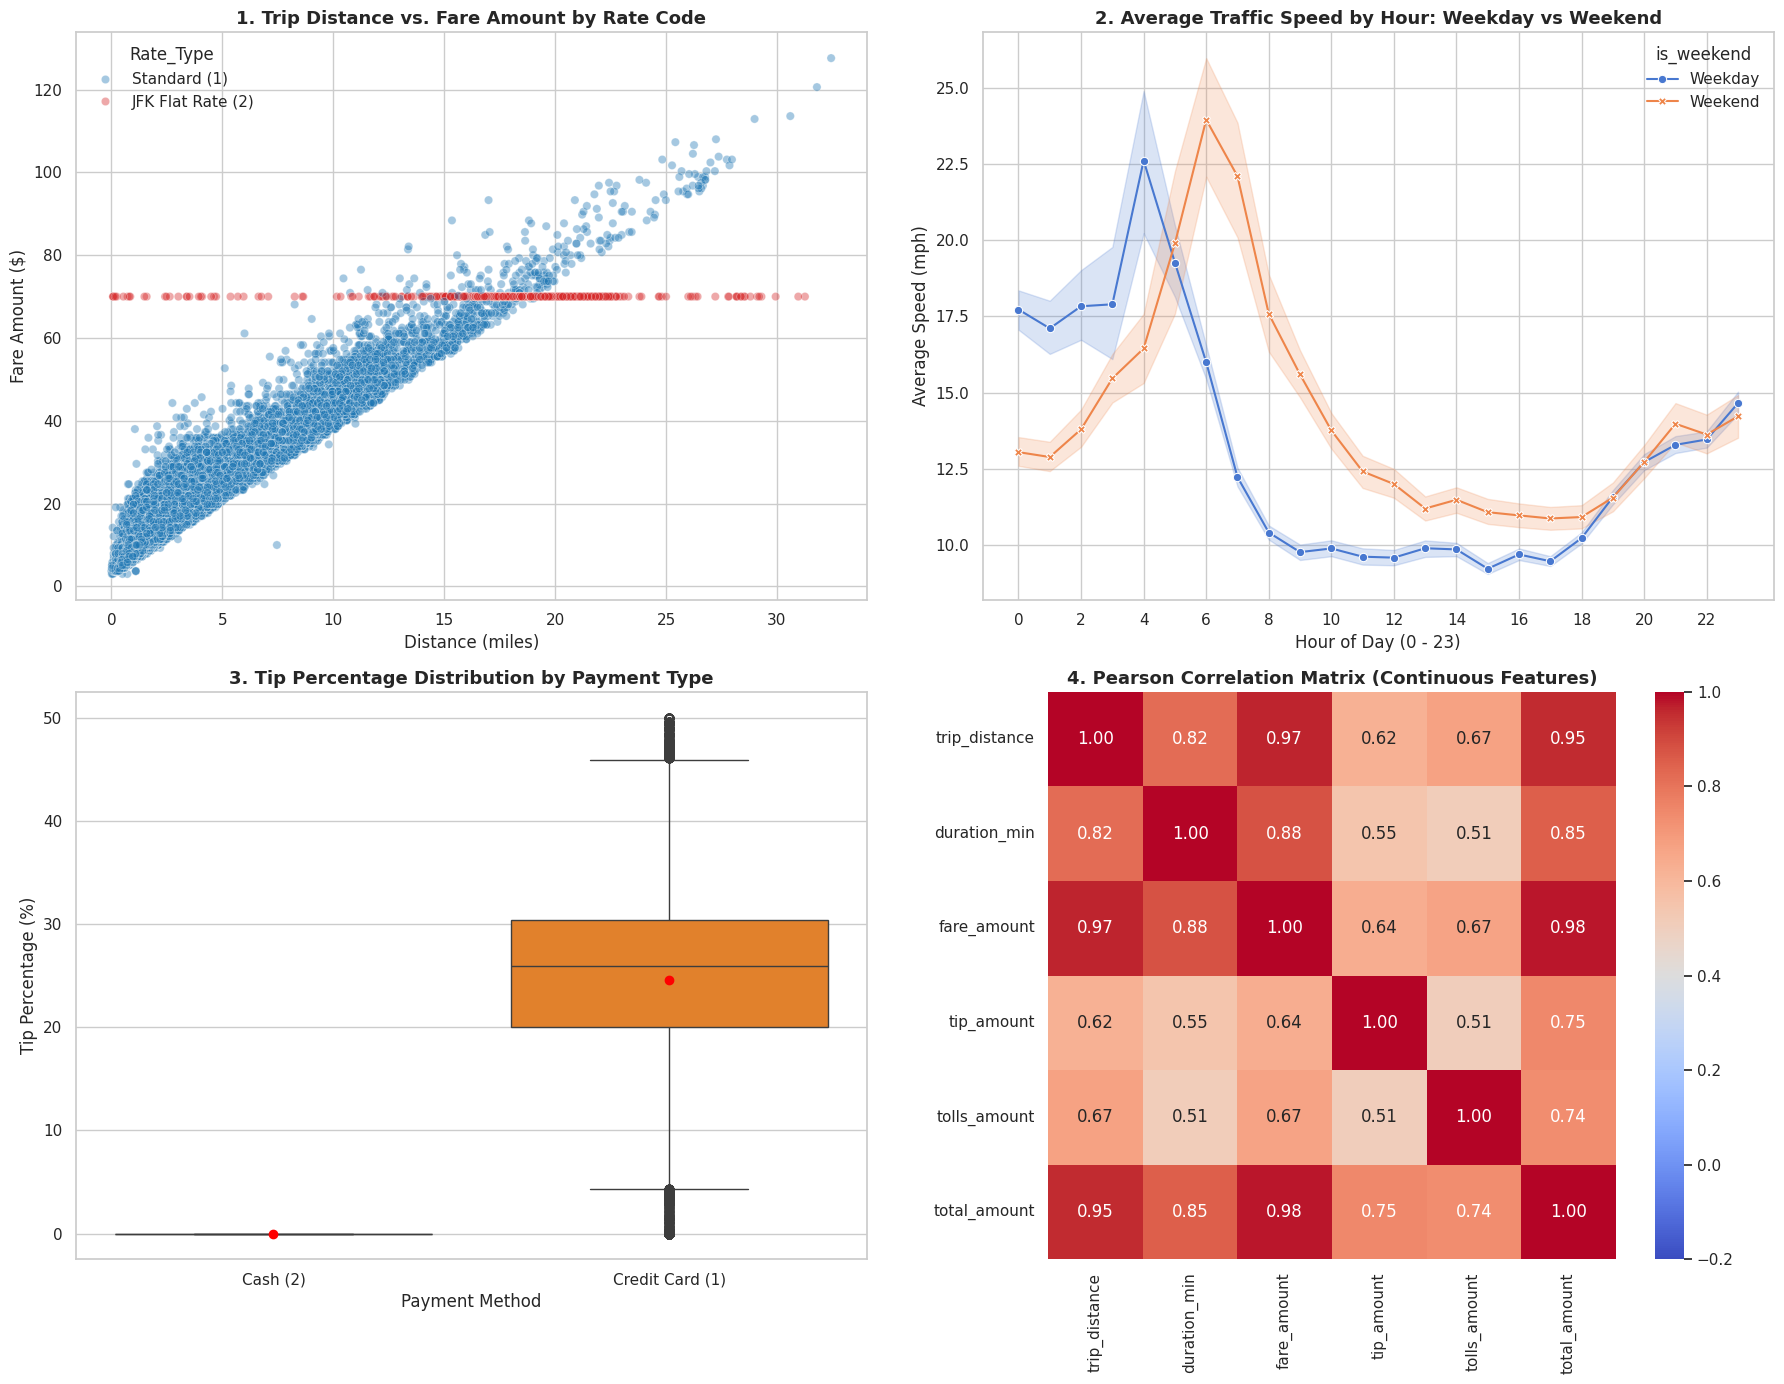

In [4]:
# ==============================================================================
# بخش ۴: تحلیل اکتشافی چندمتغیره 
# ==============================================================================



# تنظیم ظاهر نمودارها
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# مهندسی ویژگی‌های اولیه برای بررسی تعاملات
# تبدیل ستون‌های زمانی
df_raw["tpep_pickup_datetime"] = pd.to_datetime(df_raw["tpep_pickup_datetime"])
df_raw["tpep_dropoff_datetime"] = pd.to_datetime(
    df_raw["tpep_dropoff_datetime"]
)

# محاسبه مدت زمان سفر (دقیقه) و ساعت و روز
df_raw["duration_min"] = (
    df_raw["tpep_dropoff_datetime"] - df_raw["tpep_pickup_datetime"]
).dt.total_seconds() / 60.0
df_raw["pickup_hour"] = df_raw["tpep_pickup_datetime"].dt.hour
df_raw["day_of_week"] = df_raw["tpep_pickup_datetime"].dt.dayofweek
df_raw["is_weekend"] = df_raw["day_of_week"].apply(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)

# محاسبه سرعت بر حسب مایل بر ساعت
df_raw["speed_mph"] = df_raw["trip_distance"] / (df_raw["duration_min"] / 60.0)

# درصد انعام نسبت به کرایه پایه (فقط برای کرایه‌های مثبت)
df_raw["tip_pct"] = np.where(
    df_raw["fare_amount"] > 0,
    (df_raw["tip_amount"] / df_raw["fare_amount"]) * 100,
    0,
)

# نمونه‌گیری ۵۰ هزارتایی صرفاً برای رسم نمودارهای پراکندگی سنگین (Scatter plots) بدون تغییر داده‌های اصلی
sample_df = df_raw.sample(n=min(50000, len(df_raw)), random_state=42).copy()

# فیلتر مقطعی داده‌های منطقی صرفاً جهت تمیزی بصری در نمودارها
sample_clean = sample_df[
    (sample_df["trip_distance"] > 0)
    & (sample_df["trip_distance"] < 35)
    & (sample_df["fare_amount"] > 0)
    & (sample_df["fare_amount"] < 150)
    & (sample_df["duration_min"] > 1)
    & (sample_df["duration_min"] < 120)
    & (sample_df["speed_mph"] > 0)
    & (sample_df["speed_mph"] < 80)
]

# ساخت بوم نمودارها ۲ در ۲
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# ------------------------------------------------------------------------------
# نمودار ۱: تعامل مسافت و کرایه پایه به تفکیک کد نرخ (Scatter Plot)
# ------------------------------------------------------------------------------
# مقایسه نرخ استاندارد (۱) و نرخ ثابت JFK (۲)
rate_subset = sample_clean[sample_clean["RatecodeID"].isin([1.0, 2.0])].copy()
rate_subset["Rate_Type"] = rate_subset["RatecodeID"].map(
    {1.0: "Standard (1)", 2.0: "JFK Flat Rate (2)"}
)

sns.scatterplot(
    data=rate_subset,
    x="trip_distance",
    y="fare_amount",
    hue="Rate_Type",
    alpha=0.4,
    palette={"Standard (1)": "#1f77b4", "JFK Flat Rate (2)": "#d62728"},
    ax=axes[0, 0],
)
axes[0, 0].set_title(
    "1. Trip Distance vs. Fare Amount by Rate Code",
    fontsize=13,
    fontweight="bold",
)
axes[0, 0].set_xlabel("Distance (miles)")
axes[0, 0].set_ylabel("Fare Amount ($)")

# ------------------------------------------------------------------------------
# نمودار ۲: پروفایل سرعت ساعتی در روزهای کاری و آخر هفته
# ------------------------------------------------------------------------------
sns.lineplot(
    data=sample_clean,
    x="pickup_hour",
    y="speed_mph",
    hue="is_weekend",
    style="is_weekend",
    markers=True,
    dashes=False,
    errorbar=("ci", 95),
    ax=axes[0, 1],
)
axes[0, 1].set_title(
    "2. Average Traffic Speed by Hour: Weekday vs Weekend",
    fontsize=13,
    fontweight="bold",
)
axes[0, 1].set_xlabel("Hour of Day (0 - 23)")
axes[0, 1].set_ylabel("Average Speed (mph)")
axes[0, 1].set_xticks(range(0, 24, 2))

# ------------------------------------------------------------------------------
# نمودار ۳: درصد انعام بر اساس روش پرداخت 
# ------------------------------------------------------------------------------
# مقایسه کارت اعتباری (۱) با پرداخت نقدی (۲)
pay_subset = sample_clean[
    sample_clean["payment_type"].isin([1, 2])
    & (sample_clean["tip_pct"] <= 50)
].copy()
pay_subset["Payment_Method"] = pay_subset["payment_type"].map(
    {1: "Credit Card (1)", 2: "Cash (2)"}
)

sns.boxplot(
    data=pay_subset,
    x="Payment_Method",
    y="tip_pct",
    palette=["#2ca02c", "#ff7f0e"],
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
    },
    ax=axes[1, 0],
)
axes[1, 0].set_title(
    "3. Tip Percentage Distribution by Payment Type",
    fontsize=13,
    fontweight="bold",
)
axes[1, 0].set_xlabel("Payment Method")
axes[1, 0].set_ylabel("Tip Percentage (%)")

# ------------------------------------------------------------------------------
# نمودار ۴: ماتریس همبستگی متغیرهای کلیدی پیوسته
# ------------------------------------------------------------------------------
num_cols = [
    "trip_distance",
    "duration_min",
    "fare_amount",
    "tip_amount",
    "tolls_amount",
    "total_amount",
]
corr_matrix = sample_clean[num_cols].corr(method="pearson")

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.2,
    vmax=1.0,
    square=True,
    ax=axes[1, 1],
)
axes[1, 1].set_title(
    "4. Pearson Correlation Matrix (Continuous Features)",
    fontsize=13,
    fontweight="bold",
)

plt.tight_layout()
plt.show()


In [5]:
# ==============================================================================
# بخش 5: تقسیم زمانی و محاسبه خط مبنا مستقیماً روی داده‌های دست‌نخورده 
# ==============================================================================

# ۱. تقسیم زمانی بر اساس ۳ هفته اول (آموزش) و ادامه ماه (آزمون)
train_df = df_raw[df_raw['tpep_pickup_datetime'] < '2023-03-22']
test_df = df_raw[df_raw['tpep_pickup_datetime'] >= '2023-03-22']

# ۲. خط مبنای ساده: میانگین کرایه خام در مجموعه آموزش
baseline_pred = train_df['fare_amount'].mean()

# ۳. محاسبه مستقیم خطاها روی مجموعه آزمون 
errors = test_df['fare_amount'] - baseline_pred
mae = errors.abs().mean()
rmse = (errors**2).mean() ** 0.5

print("=" * 60)
print(f"تعداد داده‌های آموزش (Train): {len(train_df):,} رکورد")
print(f"تعداد داده‌های آزمون (Test):   {len(test_df):,} رکورد")
print("-" * 60)
print(f"میانگین کرایه خام آموزش (Baseline): {baseline_pred:.2f} دلار")
print(f"خطای MAE روی آزمون:                 {mae:.2f} دلار")
print(f"خطای RMSE روی آزمون:                {rmse:.2f} دلار")
print("=" * 60)


تعداد داده‌های آموزش (Train): 2,316,154 رکورد
تعداد داده‌های آزمون (Test):   1,087,612 رکورد
------------------------------------------------------------
میانگین کرایه خام آموزش (Baseline): 18.81 دلار
خطای MAE روی آزمون:                 11.83 دلار
خطای RMSE روی آزمون:                18.48 دلار


در حال خواندن فایل Parquet...
گزارش ممیزی محدوده‌های زمانی و داده‌های پرت تاریخی
کل رکوردها: 3,403,766
رکوردهای معتبر در محدوده مارس ۲۰۲۳: 3,403,577 (99.99%)
رکوردهای غیرعادی خارج از مارس ۲۰۲۳: 189 (0.0056%)
قدیمی‌ترین زمان ثبت‌شده: 2001-01-01 00:06:49
جدیدترین زمان ثبت‌شده: 2023-04-05 20:17:42

شناسایی دوره‌های پرترافیک (پیک تقاضا):
ساعات اوج تقاضا (Peak Hours):
  - ساعت 18:00 تا 19:00 با 245,604 سفر
  - ساعت 17:00 تا 18:00 با 231,834 سفر
  - ساعت 19:00 تا 20:00 با 220,698 سفر

ساعات افت تقاضا (Off-Peak Hours):
  - ساعت 04:00 تا 05:00 با 18,116 سفر
  - ساعت 05:00 تا 06:00 با 19,444 سفر
  - ساعت 03:00 تا 04:00 با 26,877 سفر

شلوغ‌ترین روزهای هفته:
  - Thursday: 598,113 سفر
  - Friday: 577,055 سفر
  - Wednesday: 570,086 سفر


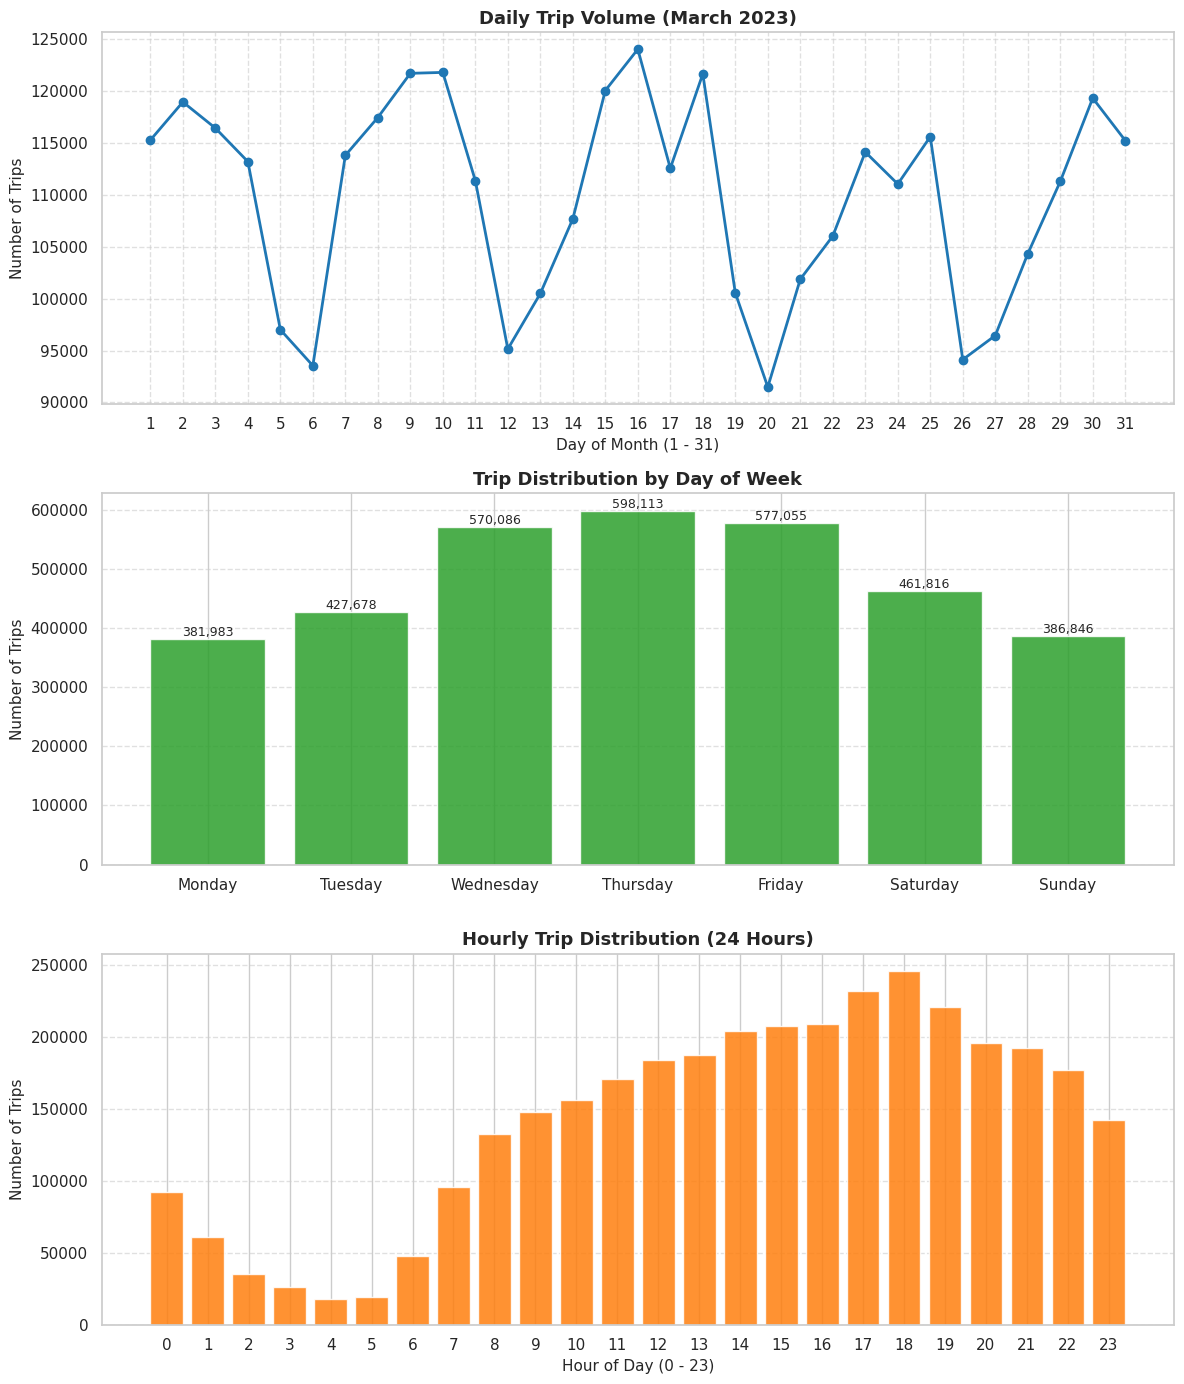

In [6]:
# ==============================================================================
# بخش 6: ممیزی زمان سفر 
# ==============================================================================


# ---------------------------------------------------------
# بارگذاری داده‌ها
# ---------------------------------------------------------
trips_file = 'yellow_tripdata_2023-03.parquet'
url = 'https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-03.parquet'

if not os.path.exists(trips_file):
    print("در حال دانلود داده‌ها...")
    urllib.request.urlretrieve(url, trips_file)

if 'df' not in locals():
    print("در حال خواندن فایل Parquet...")
    df = pd.read_parquet(trips_file)

# ---------------------------------------------------------
# تبدیل و استخراج ویژگی‌های زمانی
# ---------------------------------------------------------
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])

# استخراج تاریخ، روز هفته، و ساعت
df['pickup_date'] = df['tpep_pickup_datetime'].dt.date
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
df['pickup_dayofweek'] = df['tpep_pickup_datetime'].dt.day_name()
# ترتیب استاندارد روزهای هفته
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']


# ---------------------------------------------------------
#  ممیزی ناهنجاری‌های تاریخی 
# ---------------------------------------------------------
start_date = pd.Timestamp('2023-03-01 00:00:00')
end_date = pd.Timestamp('2023-03-31 23:59:59')

in_scope_mask = (df['tpep_pickup_datetime'] >= start_date) & (df['tpep_pickup_datetime'] <= end_date)
out_of_scope_count = (~in_scope_mask).sum()
total_records = len(df)

print("=" * 65)
print("گزارش ممیزی محدوده‌های زمانی و داده‌های پرت تاریخی")
print("=" * 65)
print(f"کل رکوردها: {total_records:,}")
print(f"رکوردهای معتبر در محدوده مارس ۲۰۲۳: {in_scope_mask.sum():,} ({in_scope_mask.mean()*100:.2f}%)")
print(f"رکوردهای غیرعادی خارج از مارس ۲۰۲۳: {out_of_scope_count:,} ({(out_of_scope_count/total_records)*100:.4f}%)")

if out_of_scope_count > 0:
    min_date = df['tpep_pickup_datetime'].min()
    max_date = df['tpep_pickup_datetime'].max()
    print(f"قدیمی‌ترین زمان ثبت‌شده: {min_date}")
    print(f"جدیدترین زمان ثبت‌شده: {max_date}")

# ---------------------------------------------------------
# تحلیل توزیع زمانی (فقط روی رکوردهای ماه مارس برای نمایش صحیح تقویمی)
# ---------------------------------------------------------
df_march = df[in_scope_mask].copy()

# توزیع ساعتی
hourly_dist = df_march['pickup_hour'].value_counts().sort_index()

# توزیع روزهای هفته
dow_dist = df_march['pickup_dayofweek'].value_counts().reindex(days_order)

# توزیع روزانه (۳۱ روز مارس)
daily_dist = df_march['tpep_pickup_datetime'].dt.day.value_counts().sort_index()

print("\n" + "=" * 65)
print("شناسایی دوره‌های پرترافیک (پیک تقاضا):")
print("=" * 65)
top_3_hours = hourly_dist.nlargest(3)
low_3_hours = hourly_dist.nsmallest(3)

print("ساعات اوج تقاضا (Peak Hours):")
for hr, cnt in top_3_hours.items():
    print(f"  - ساعت {hr:02d}:00 تا {hr+1:02d}:00 با {cnt:,} سفر")

print("\nساعات افت تقاضا (Off-Peak Hours):")
for hr, cnt in low_3_hours.items():
    print(f"  - ساعت {hr:02d}:00 تا {hr+1:02d}:00 با {cnt:,} سفر")

print("\nشلوغ‌ترین روزهای هفته:")
for day, cnt in dow_dist.nlargest(3).items():
    print(f"  - {day}: {cnt:,} سفر")

# ---------------------------------------------------------
# رسم نمودارهای سه‌گانه ممیزی زمان
# ---------------------------------------------------------
fig, axes = plt.subplots(3, 1, figsize=(12, 14))

# نمودار روزانه مارس ۲۰۲۳
axes[0].plot(daily_dist.index, daily_dist.values, marker='o', color='#1f77b4', linewidth=2)
axes[0].set_title('Daily Trip Volume (March 2023)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Day of Month (1 - 31)', fontsize=11)
axes[0].set_ylabel('Number of Trips', fontsize=11)
axes[0].set_xticks(range(1, 32))
axes[0].grid(True, linestyle='--', alpha=0.6)

# نمودار روزهای هفته
bars = axes[1].bar(days_order, dow_dist.values, color='#2ca02c', alpha=0.85)
axes[1].set_title('Trip Distribution by Day of Week', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Number of Trips', fontsize=11)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval, f'{int(yval):,}', ha='center', va='bottom', fontsize=9)

# نمودار ساعتی شبانه‌روز
axes[2].bar(hourly_dist.index, hourly_dist.values, color='#ff7f0e', alpha=0.85)
axes[2].set_title('Hourly Trip Distribution (24 Hours)', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Hour of Day (0 - 23)', fontsize=11)
axes[2].set_ylabel('Number of Trips', fontsize=11)
axes[2].set_xticks(range(0, 24))
axes[2].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


گزارش ممیزی سازگاری متغیرهای سفر (Consistency Audit Report)
تعداد کل رکوردهای دیتاست: 3,403,766

۱. رکوردهای ناسازگار و غیرممکن شناسایی‌شده:
  - مسافت مثبت با زمان صفر یا منفی: 449 مورد (0.013%)
  - سرعت غیرواقعی و ناممکن فیزیکی (> 80 mph): 2,232 مورد (0.066%)
  - مسافت صفر با کرایه مثبت بالا (> 5$): 31,487 مورد (0.925%)
  - مسافت طولانی (> 2 مایل) با کرایه صفر یا منفی: 9,580 مورد (0.281%)
  - کل کرایه‌های منفی (Negative Fares): 29,677 مورد (0.872%)

۲. ماتریس همبستگی (سازگاری منطقی) میان متغیرها در سفرهای معتبر:
                Duration (min)  Distance (mi)  Fare ($)  Speed (mph)
Duration (min)           1.000          0.815     0.851        0.004
Distance (mi)            0.815          1.000     0.953        0.055
Fare ($)                 0.851          0.953     1.000        0.041
Speed (mph)              0.004          0.055     0.041        1.000
گزارش نتایج ممیزی داده‌های ناقص و الگوهای غیرمعمول زمانی
۱. مقادیر خالی زمان سوار شدن (Null Pickup): 0
۲. مقادیر خالی زمان پیاده شدن (Nu

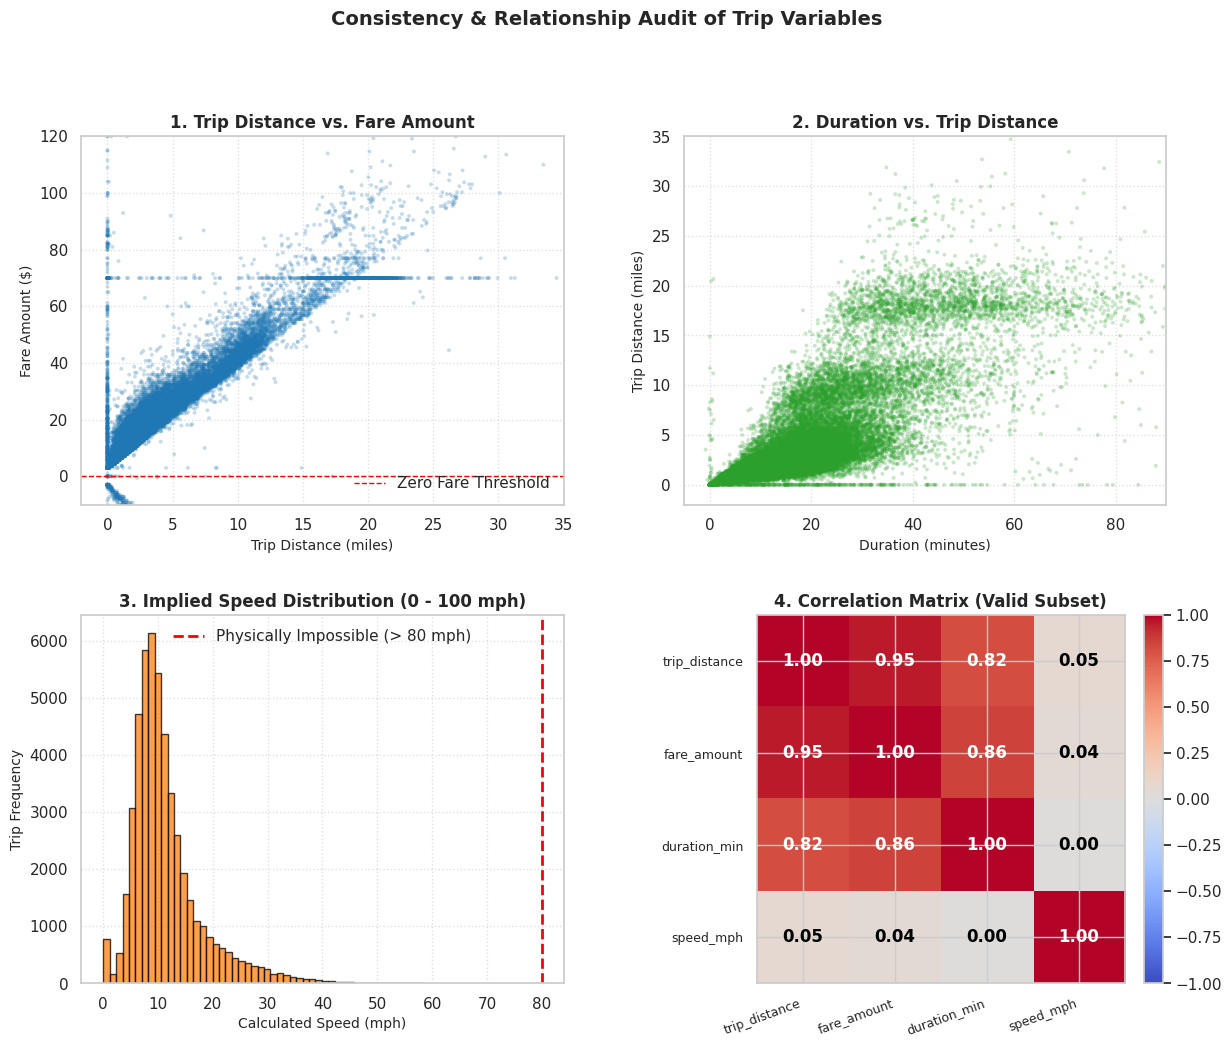

In [7]:
# ==============================================================================
#  بخش 7: ممیزی سازگاری متغیرهای سفر 
# ==============================================================================


# اطمینان از تبدیل تاریخ‌ها
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])

# محاسبه ویژگی‌های مشتق‌شده
# مدت زمان بر حسب دقیقه
duration_min = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60.0
# مدت زمان بر حسب ساعت برای محاسبه سرعت
duration_hours = duration_min / 60.0

# سرعت بر حسب مایل بر ساعت (جلوگیری از تقسیم بر صفر)
speed_mph = np.where(duration_hours > 0, df['trip_distance'] / duration_hours, np.nan)

total_records = len(df)

# تعریف و شمارش سناریوهای ناسازگاری
# زمان صفر یا منفی هم‌زمان با مسافت مثبت
cond_time_anomaly = (duration_min <= 0) & (df['trip_distance'] > 0)

# سرعت‌های غیرممکن فیزیکی (بیش از ۸۰ مایل بر ساعت در سطح شهر)
cond_impossible_speed = (speed_mph > 80)

# مسافت صفر اما کرایه پایه قابل توجه (> ۵ دلار)
cond_zero_dist_high_fare = (df['trip_distance'] == 0) & (df['fare_amount'] > 5.0)

# مسافت قابل توجه (> ۲ مایل) با کرایه پایه صفر یا منفی
cond_high_dist_zero_fare = (df['trip_distance'] > 2.0) & (df['fare_amount'] <= 0)

# کرایه منفی (تراکنش‌های برگشتی یا خطای سیستم)
cond_negative_fare = (df['fare_amount'] < 0)

# همبستگی میان متغیرهای پیوسته معتبر (برای بررسی کلی رابطه خطی)
valid_mask = (duration_min > 0) & (duration_min < 180) & (df['trip_distance'] > 0) & (df['trip_distance'] < 100) & (df['fare_amount'] > 0)
corr_matrix = pd.DataFrame({
    'Duration (min)': duration_min[valid_mask],
    'Distance (mi)': df.loc[valid_mask, 'trip_distance'],
    'Fare ($)': df.loc[valid_mask, 'fare_amount'],
    'Speed (mph)': speed_mph[valid_mask]
}).corr()

# چاپ گزارش مدون
print("=" * 70)
print("گزارش ممیزی سازگاری متغیرهای سفر (Consistency Audit Report)")
print("=" * 70)
print(f"تعداد کل رکوردهای دیتاست: {total_records:,}\n")

print("۱. رکوردهای ناسازگار و غیرممکن شناسایی‌شده:")
print(f"  - مسافت مثبت با زمان صفر یا منفی: {cond_time_anomaly.sum():,} مورد ({(cond_time_anomaly.sum()/total_records)*100:.3f}%)")
print(f"  - سرعت غیرواقعی و ناممکن فیزیکی (> 80 mph): {np.nansum(cond_impossible_speed):,} مورد ({(np.nansum(cond_impossible_speed)/total_records)*100:.3f}%)")
print(f"  - مسافت صفر با کرایه مثبت بالا (> 5$): {cond_zero_dist_high_fare.sum():,} مورد ({(cond_zero_dist_high_fare.sum()/total_records)*100:.3f}%)")
print(f"  - مسافت طولانی (> 2 مایل) با کرایه صفر یا منفی: {cond_high_dist_zero_fare.sum():,} مورد ({(cond_high_dist_zero_fare.sum()/total_records)*100:.3f}%)")
print(f"  - کل کرایه‌های منفی (Negative Fares): {cond_negative_fare.sum():,} مورد ({(cond_negative_fare.sum()/total_records)*100:.3f}%)")

print("\n" + "=" * 70)
print("۲. ماتریس همبستگی (سازگاری منطقی) میان متغیرها در سفرهای معتبر:")
print("=" * 70)
print(corr_matrix.round(3).to_string())
print("=" * 70)


# ==============================================================================
# بررسی دقیق داده‌های ناقص و الگوهای غیرمعمول زمانی 
# ==============================================================================

# بررسی مقادیر گم‌شده یا خالی (Missing / NaT)
missing_pickups = df['tpep_pickup_datetime'].isna().sum()
missing_dropoffs = df['tpep_dropoff_datetime'].isna().sum()

# رکوردهای با تاریخ خارج از ماه مارس ۲۰۲۳
start_march = pd.Timestamp('2023-03-01 00:00:00')
end_march = pd.Timestamp('2023-03-31 23:59:59')

out_of_range_mask = (df['tpep_pickup_datetime'] < start_march) | (df['tpep_pickup_datetime'] > end_march)
out_of_range_count = out_of_range_mask.sum()

# خطای منطق زمانی: سفرهایی که زمان پیاده‌شدن قبل از سوارشدن است
negative_time_mask = df['tpep_dropoff_datetime'] < df['tpep_pickup_datetime']
negative_time_count = negative_time_mask.sum()

# سفرهای با مدت زمان صفر ثانیه
zero_time_mask = df['tpep_dropoff_datetime'] == df['tpep_pickup_datetime']
zero_time_count = zero_time_mask.sum()

# سفرهای غیرعادی بسیار طولانی (مثلاً بیشتر از ۲۴ ساعت در یک سفر شهری)
duration_hours = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 3600
extreme_duration_count = (duration_hours > 24).sum()

print("=" * 60)
print("گزارش نتایج ممیزی داده‌های ناقص و الگوهای غیرمعمول زمانی")
print("=" * 60)
print(f"۱. مقادیر خالی زمان سوار شدن (Null Pickup): {missing_pickups:,}")
print(f"۲. مقادیر خالی زمان پیاده شدن (Null Dropoff): {missing_dropoffs:,}")
print(f"۳. رکوردهای خارج از بازه مارس ۲۰۲۳: {out_of_range_count:,} رکورد")
if out_of_range_count > 0:
    print(f"   - حداقل تاریخ مشاهده شده: {df['tpep_pickup_datetime'].min()}")
    print(f"   - حداکثر تاریخ مشاهده شده: {df['tpep_pickup_datetime'].max()}")
print(f"۴. سفرهای با زمان معکوس (Dropoff قبل از Pickup): {negative_time_count:,} رکورد")
print(f"۵. سفرهای با مدت دقیقاً صفر ثانیه: {zero_time_count:,} رکورد")
print(f"۶. سفرهای با مدت غیرواقعی (> ۲۴ ساعت): {extreme_duration_count:,} رکورد")
print("=" * 60)


# ==============================================================================
# مصورسازی روابط و سازگاری میان متغیرهای سفر
# ==============================================================================


# محاسبه متغیرهای مورد نیاز
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])

duration_min = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 60.0
duration_hours = duration_min / 60.0
speed_mph = np.where(duration_hours > 0, df['trip_distance'] / duration_hours, np.nan)

# ساخت یک دیتافریم سبک و نمونه‌گیری ۵۰,۰۰۰ تایی برای رسم سریع و شفاف
plot_df = pd.DataFrame({
    'trip_distance': df['trip_distance'],
    'fare_amount': df['fare_amount'],
    'duration_min': duration_min,
    'speed_mph': speed_mph
})

sample_df = plot_df.sample(n=min(50000, len(plot_df)), random_state=42)

# تنظیم بوم نمودارها (۲ در ۲)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
plt.subplots_adjust(hspace=0.3, wspace=0.25)

# رابطه مسافت و کرایه (شناسایی نرخ ثابت و کرایه‌های پرت)
axes[0, 0].scatter(sample_df['trip_distance'], sample_df['fare_amount'], 
                   alpha=0.25, s=8, color='#1f77b4', edgecolors='none')
axes[0, 0].set_title('1. Trip Distance vs. Fare Amount', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Trip Distance (miles)', fontsize=10)
axes[0, 0].set_ylabel('Fare Amount ($)', fontsize=10)
axes[0, 0].set_xlim(-2, 35)
axes[0, 0].set_ylim(-10, 120)
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=1, label='Zero Fare Threshold')
axes[0, 0].grid(True, linestyle=':', alpha=0.6)
axes[0, 0].legend()

# رابطه مدت سفر و مسافت
axes[0, 1].scatter(sample_df['duration_min'], sample_df['trip_distance'], 
                   alpha=0.25, s=8, color='#2ca02c', edgecolors='none')
axes[0, 1].set_title('2. Duration vs. Trip Distance', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Duration (minutes)', fontsize=10)
axes[0, 1].set_ylabel('Trip Distance (miles)', fontsize=10)
axes[0, 1].set_xlim(-5, 90)
axes[0, 1].set_ylim(-2, 35)
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# توزیع سرعت و نمایش مرز سرعت غیرممکن فیزیکی
valid_speeds = sample_df['speed_mph'].dropna()
axes[1, 0].hist(valid_speeds[(valid_speeds >= 0) & (valid_speeds <= 100)], 
                bins=50, color='#ff7f0e', edgecolor='black', alpha=0.75)
axes[1, 0].axvline(80, color='red', linestyle='--', linewidth=2, label='Physically Impossible (> 80 mph)')
axes[1, 0].set_title('3. Implied Speed Distribution (0 - 100 mph)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Calculated Speed (mph)', fontsize=10)
axes[1, 0].set_ylabel('Trip Frequency', fontsize=10)
axes[1, 0].grid(True, linestyle=':', alpha=0.6)
axes[1, 0].legend()

# هیت‌مپ همبستگی میان ۴ متغیر
corr = plot_df[(plot_df['duration_min'] > 0) & (plot_df['duration_min'] < 120) & 
               (plot_df['trip_distance'] > 0) & (plot_df['trip_distance'] < 50) & 
               (plot_df['fare_amount'] > 0)].corr()

im = axes[1, 1].imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
axes[1, 1].set_title('4. Correlation Matrix (Valid Subset)', fontsize=12, fontweight='bold')
axes[1, 1].set_xticks(range(len(corr.columns)))
axes[1, 1].set_yticks(range(len(corr.columns)))
axes[1, 1].set_xticklabels(corr.columns, rotation=20, ha='right', fontsize=9)
axes[1, 1].set_yticklabels(corr.columns, fontsize=9)
fig.colorbar(im, ax=axes[1, 1], fraction=0.046, pad=0.04)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        text = axes[1, 1].text(j, i, f"{corr.iloc[i, j]:.2f}",
                               ha="center", va="center", color="black" if abs(corr.iloc[i, j]) < 0.7 else "white",
                               fontweight='bold')

plt.suptitle('Consistency & Relationship Audit of Trip Variables', fontsize=14, fontweight='bold', y=0.995)
plt.show()



۱. توزیع و سهم مناطق کلان‌شهری (Borough Share) - بررسی عدم توازن:
               Pickup Count  Pickup Share (%)  Dropoff Count  Dropoff Share (%)
Bronx                  5690              0.17          20565               0.60
Brooklyn              22014              0.65         129893               3.82
EWR                     427              0.01           9474               0.28
Manhattan           3013786             88.54        3010446              88.44
Queens               327084              9.61         184180               5.41
Staten Island           292              0.01           1088               0.03
Unknown               30908              0.91          35898               1.05

۲. ۱۰ ناحیه پرتقاضای مبدأ (Top 10 Pickup Zones):
   1. JFK Airport                        : 169,845 سفر (4.99%)
   2. Midtown Center                     : 160,946 سفر (4.73%)
   3. Upper East Side South              : 153,939 سفر (4.52%)
   4. Upper East Side North              : 139,501 سفر 

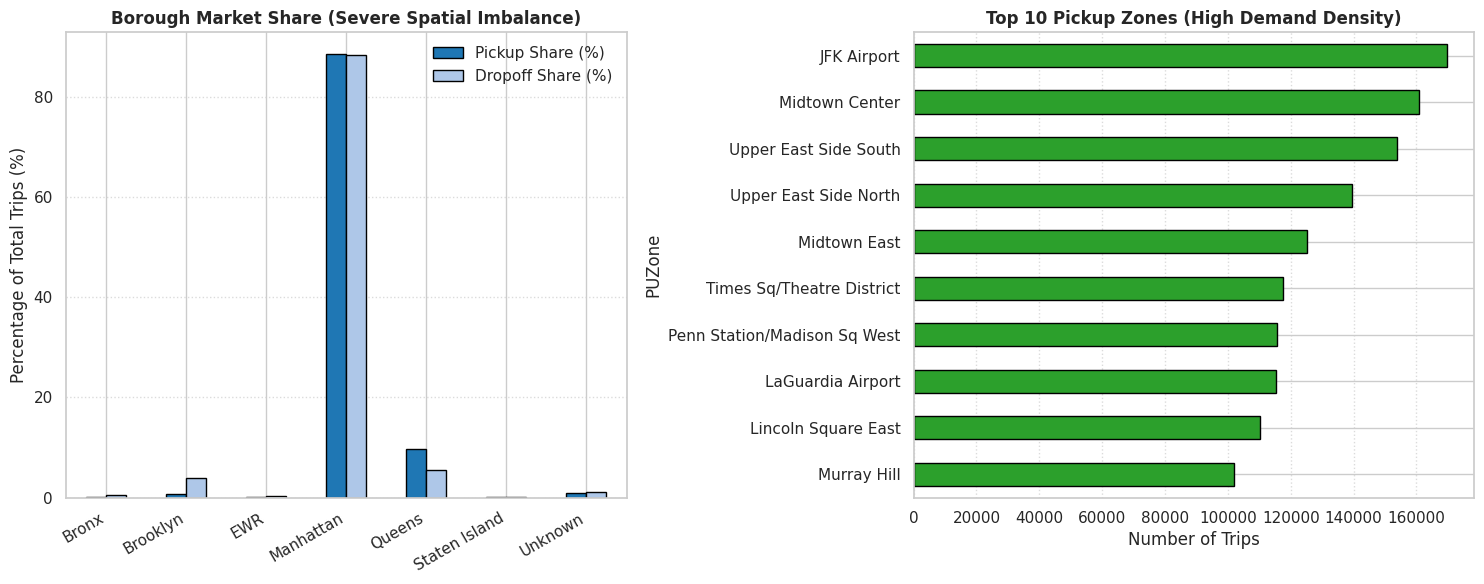

In [8]:
# ==============================================================================
# بخش 8: تحلیل نمای مکانی اولیه و بررسی عدم توازن مبدأ و مقصد 
# ==============================================================================


# بارگذاری فایل راهنمای مناطق در صورت عدم وجود در متغیرها
try:
    zones_df
except NameError:
    zones_url = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
    zones_df = pd.read_csv(zones_url)

# ادغام اسامی مناطق و بخش‌ها (Boroughs) برای مبدأ و مقصد
# پیوند برای مبدأ
df_spatial = df[['PULocationID', 'DOLocationID']].dropna().copy()
df_spatial = df_spatial.merge(
    zones_df[['LocationID', 'Borough', 'Zone']], 
    left_on='PULocationID', 
    right_on='LocationID', 
    how='left'
).rename(columns={'Borough': 'PUBorough', 'Zone': 'PUZone'}).drop(columns=['LocationID'])

# پیوند برای مقصد
df_spatial = df_spatial.merge(
    zones_df[['LocationID', 'Borough', 'Zone']], 
    left_on='DOLocationID', 
    right_on='LocationID', 
    how='left'
).rename(columns={'Borough': 'DOBorough', 'Zone': 'DOZone'}).drop(columns=['LocationID'])

total_trips = len(df_spatial)

# محاسبه سهم هر بخش (Borough) از کل مبدأها و مقصدها
borough_summary = pd.DataFrame({
    'Pickup Count': df_spatial['PUBorough'].value_counts(),
    'Pickup Share (%)': (df_spatial['PUBorough'].value_counts() / total_trips * 100).round(2),
    'Dropoff Count': df_spatial['DOBorough'].value_counts(),
    'Dropoff Share (%)': (df_spatial['DOBorough'].value_counts() / total_trips * 100).round(2)
}).fillna(0)

# ۱۰ ناحیه پرتکرار مبدأ و مقصد
top10_pickup = df_spatial['PUZone'].value_counts().head(10)
top10_dropoff = df_spatial['DOZone'].value_counts().head(10)

# ۵. پرتقاضاترین جفت مسیرها
df_spatial['OD_Pair'] = df_spatial['PUZone'] + '  -->  ' + df_spatial['DOZone']
top_od_pairs = df_spatial['OD_Pair'].value_counts().head(10)

# نمایش نتایج آماری متنی
print("=" * 75)
print("۱. توزیع و سهم مناطق کلان‌شهری (Borough Share) - بررسی عدم توازن:")
print("=" * 75)
print(borough_summary.to_string())

print("\n" + "=" * 75)
print("۲. ۱۰ ناحیه پرتقاضای مبدأ (Top 10 Pickup Zones):")
print("=" * 75)
for idx, (zone, count) in enumerate(top10_pickup.items(), 1):
    print(f"  {idx:2d}. {zone:<35}: {count:,} سفر ({count/total_trips*100:.2f}%)")

print("\n" + "=" * 75)
print("۳. پرترددترین مسیرهای مبدأ-مقصد (Top OD Pairs):")
print("=" * 75)
for idx, (od, count) in enumerate(top_od_pairs.items(), 1):
    print(f"  {idx:2d}. {od:<45}: {count:,} سفر")
print("=" * 75)

# مصورسازی توزیع مکانی (سهم مناطق و ۱۰ ناحیه برتر)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# نمودار سهم بخش‌ها
borough_summary[['Pickup Share (%)', 'Dropoff Share (%)']].plot(
    kind='bar', ax=axes[0], color=['#1f77b4', '#aec7e8'], edgecolor='black'
)
axes[0].set_title('Borough Market Share (Severe Spatial Imbalance)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Percentage of Total Trips (%)')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
axes[0].grid(axis='y', linestyle=':', alpha=0.7)

# نمودار ۱۰ ناحیه برتر مبدأ
top10_pickup.sort_values().plot(kind='barh', ax=axes[1], color='#2ca02c', edgecolor='black')
axes[1].set_title('Top 10 Pickup Zones (High Demand Density)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Trips')
axes[1].grid(axis='x', linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()
